In [1]:
# Vérification de l'environnement
# Si une bibliothèque manque, installe-la séparément avec %pip install nom_bibliotheque
import numpy as np
import pandas as pd
import scipy
import sklearn

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("SciPy :", scipy.__version__)
print("Scikit-learn :", sklearn.__version__)


NumPy : 1.26.4
Pandas : 2.2.3
SciPy : 1.14.1
Scikit-learn : 1.5.2


In [2]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")




In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape


(7043, 21)

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [7]:
missing_report = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_percentage': (df.isnull().sum() / len(df)) * 100
})

missing_report

,missing_count,missing_percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [8]:
df.duplicated().sum()

0

In [9]:
df['customerID'].duplicated().sum()

0

In [10]:
df['customerID'].nunique()

7043

In [11]:
df.shape

(7043, 21)

In [12]:
for col in df.select_dtypes(include='object').columns:
    print(col)
    print(df[col].unique())
    print('-' * 40)

customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
----------------------------------------
gender
['Female' 'Male']
----------------------------------------
Partner
['Yes' 'No']
----------------------------------------
Dependents
['No' 'Yes']
----------------------------------------
PhoneService
['No' 'Yes']
----------------------------------------
MultipleLines
['No phone service' 'No' 'Yes']
----------------------------------------
InternetService
['DSL' 'Fiber optic' 'No']
----------------------------------------
OnlineSecurity
['No' 'Yes' 'No internet service']
----------------------------------------
OnlineBackup
['Yes' 'No' 'No internet service']
----------------------------------------
DeviceProtection
['No' 'Yes' 'No internet service']
----------------------------------------
TechSupport
['No' 'Yes' 'No internet service']
----------------------------------------
StreamingTV
['No' 'Yes' 'No internet service']
------------------------

In [13]:
df['TotalCharges'].head(20)

0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
15    7895.15
16    1022.95
17    7382.25
18     528.35
19     1862.9
Name: TotalCharges, dtype: object

In [14]:
df['TotalCharges'].dtype

dtype('O')

In [15]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [16]:
df['TotalCharges'].isnull().sum()

11

In [17]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [18]:
df[df['TotalCharges'].isnull()][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [19]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

Eleven missing values were identified in TotalCharges. All concerned customers had tenure = 0, indicating newly acquired customers. These missing values were therefore replaced with 0 rather than imputed using a statistical measure.

In [20]:
df['TotalCharges'].isnull().sum()

0

In [21]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [22]:
# 2. Statistiques numériques
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [23]:
# 3. Répartition de la cible
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [24]:
df = df.rename(columns={
    'customerID': 'id_client',
    'gender': 'sexe',
    'SeniorCitizen': 'senior',
    'Partner': 'partenaire',
    'Dependents': 'personnes_a_charge',
    'tenure': 'anciennete_mois',
    'PhoneService': 'service_telephone',
    'InternetService': 'service_internet',
    'Contract': 'type_contrat',
    'PaymentMethod': 'mode_paiement',
    'MonthlyCharges': 'frais_mensuels',
    'TotalCharges': 'frais_totaux',
    'Churn': 'resiliation'
})

In [25]:
df.head()

,id_client,sexe,senior,partenaire,personnes_a_charge,anciennete_mois,service_telephone,MultipleLines,service_internet,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,type_contrat,PaperlessBilling,mode_paiement,frais_mensuels,frais_totaux,resiliation
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [26]:
df['resiliation'].value_counts()

resiliation
No     5174
Yes    1869
Name: count, dtype: int64

In [27]:
df.groupby('type_contrat')['resiliation'].value_counts()

type_contrat    resiliation
Month-to-month  No             2220
                Yes            1655
One year        No             1307
                Yes             166
Two year        No             1647
                Yes              48
Name: count, dtype: int64

In [28]:
# 1. Taux global de résiliation
df['resiliation'].value_counts(normalize=True) * 100

resiliation
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [29]:
# 2. Résiliation selon le type de contrat
pd.crosstab(
    df['type_contrat'],
    df['resiliation'],
    normalize='index'
) * 100

resiliation,No,Yes
type_contrat,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [30]:
# 3. Ancienneté moyenne selon la résiliation
df.groupby('resiliation')['anciennete_mois'].mean()

resiliation
No     37.569965
Yes    17.979133
Name: anciennete_mois, dtype: float64

In [31]:
# 4. Frais mensuels moyens selon la résiliation
df.groupby('resiliation')['frais_mensuels'].mean()

resiliation
No     61.265124
Yes    74.441332
Name: frais_mensuels, dtype: float64

In [32]:
# 5. Service internet vs résiliation
pd.crosstab(
    df['service_internet'],
    df['resiliation'],
    normalize='index'
) * 100

resiliation,No,Yes
service_internet,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [33]:
# 6. Mode de paiement vs résiliation
pd.crosstab(
    df['mode_paiement'],
    df['resiliation'],
    normalize='index'
) * 100

resiliation,No,Yes
mode_paiement,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [34]:
eda_summary = pd.DataFrame({
    'taux_resiliation_global': [
        (df['resiliation'] == 'Yes').mean() * 100
    ],
    'anciennete_moyenne_resilies': [
        df.loc[df['resiliation'] == 'Yes', 'anciennete_mois'].mean()
    ],
    'anciennete_moyenne_non_resilies': [
        df.loc[df['resiliation'] == 'No', 'anciennete_mois'].mean()
    ],
    'frais_mensuels_moyens_resilies': [
        df.loc[df['resiliation'] == 'Yes', 'frais_mensuels'].mean()
    ],
    'frais_mensuels_moyens_non_resilies': [
        df.loc[df['resiliation'] == 'No', 'frais_mensuels'].mean()
    ]
})

eda_summary.round(2)

,taux_resiliation_global,anciennete_moyenne_resilies,anciennete_moyenne_non_resilies,frais_mensuels_moyens_resilies,frais_mensuels_moyens_non_resilies
0,26.54,17.98,37.57,74.44,61.27


In [35]:
# 1. Nouveau client
df['client_nouveau'] = (
    df['anciennete_mois'] <= 12
).astype(int)

In [36]:
# 2. Contrat mensuel
df['contrat_mensuel'] = (
    df['type_contrat'] == 'Month-to-month'
).astype(int)

In [37]:
# 3. Paiement automatique
df['paiement_automatique'] = df['mode_paiement'].isin([
    'Bank transfer (automatic)',
    'Credit card (automatic)'
]).astype(int)

In [38]:
df.columns

Index(['id_client', 'sexe', 'senior', 'partenaire', 'personnes_a_charge',
       'anciennete_mois', 'service_telephone', 'MultipleLines',
       'service_internet', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'type_contrat', 'PaperlessBilling', 'mode_paiement', 'frais_mensuels',
       'frais_totaux', 'resiliation', 'client_nouveau', 'contrat_mensuel',
       'paiement_automatique'],
      dtype='object')

In [39]:
df = df.rename(columns={
    'MultipleLines': 'lignes_multiples',
    'OnlineSecurity': 'securite_en_ligne',
    'OnlineBackup': 'sauvegarde_en_ligne',
    'DeviceProtection': 'protection_appareil',
    'TechSupport': 'support_technique',
    'StreamingTV': 'streaming_tv',
    'StreamingMovies': 'streaming_films',
    'PaperlessBilling': 'facturation_sans_papier'
})

In [40]:
df.columns

Index(['id_client', 'sexe', 'senior', 'partenaire', 'personnes_a_charge',
       'anciennete_mois', 'service_telephone', 'lignes_multiples',
       'service_internet', 'securite_en_ligne', 'sauvegarde_en_ligne',
       'protection_appareil', 'support_technique', 'streaming_tv',
       'streaming_films', 'type_contrat', 'facturation_sans_papier',
       'mode_paiement', 'frais_mensuels', 'frais_totaux', 'resiliation',
       'client_nouveau', 'contrat_mensuel', 'paiement_automatique'],
      dtype='object')

In [41]:
services = [
    'service_telephone',
    'securite_en_ligne',
    'sauvegarde_en_ligne',
    'protection_appareil',
    'support_technique',
    'streaming_tv',
    'streaming_films'
]

df['nombre_services'] = (
    df[services]
    .apply(lambda ligne: (ligne == 'Yes').sum(), axis=1)
)

In [42]:
nombre_services = 4

In [43]:
df['resiliation_binaire'] = df['resiliation'].map({
    'No': 0,
    'Yes': 1
})

In [44]:
df[
    [
        'anciennete_mois',
        'client_nouveau',
        'type_contrat',
        'contrat_mensuel',
        'mode_paiement',
        'paiement_automatique',
        'nombre_services',
        'resiliation',
        'resiliation_binaire'
    ]
].head(10)

,anciennete_mois,client_nouveau,type_contrat,contrat_mensuel,mode_paiement,paiement_automatique,nombre_services,resiliation,resiliation_binaire
0,1,1,Month-to-month,1,Electronic check,0,1,No,0
1,34,0,One year,0,Mailed check,0,3,No,0
2,2,1,Month-to-month,1,Mailed check,0,3,Yes,1
3,45,0,One year,0,Bank transfer (automatic),1,3,No,0
4,2,1,Month-to-month,1,Electronic check,0,1,Yes,1
5,8,1,Month-to-month,1,Electronic check,0,4,Yes,1
6,22,0,Month-to-month,1,Credit card (automatic),1,3,No,0
7,10,1,Month-to-month,1,Mailed check,0,1,No,0
8,28,0,Month-to-month,1,Electronic check,0,5,Yes,1
9,62,0,One year,0,Bank transfer (automatic),1,3,No,0


## Préparation du Machine Learning

In [45]:
y = df['resiliation_binaire']

In [46]:
X = df.drop(
    columns=[
        'id_client',
        'resiliation',
        'resiliation_binaire'
    ]
)

In [47]:
from sklearn.model_selection import train_test_split

# 1) Réserver 15 % des données pour le TEST FINAL.
# Ce jeu ne doit pas servir au choix du modèle ni du seuil.
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# 2) Séparer les 85 % restants en ~70 % Train et ~15 % Validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,
    random_state=42,
    stratify=y_temp
)


In [48]:
print("Train      :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test final :", X_test.shape, y_test.shape)

print("\nRépartition de la cible :")
print("Train      :", y_train.mean().round(3))
print("Validation :", y_val.mean().round(3))
print("Test       :", y_test.mean().round(3))


Train      : (4929, 23) (4929,)
Validation : (1057, 23) (1057,)
Test final : (1057, 23) (1057,)

Répartition de la cible :
Train      : 0.265
Validation : 0.266
Test       : 0.265


In [49]:
print("Répartition train :")
print(y_train.value_counts(normalize=True) * 100)

print("\nRépartition test :")
print(y_test.value_counts(normalize=True) * 100)

Répartition train :
resiliation_binaire
0    73.463177
1    26.536823
Name: proportion, dtype: float64

Répartition test :
resiliation_binaire
0    73.509934
1    26.490066
Name: proportion, dtype: float64


In [50]:
colonnes_numeriques = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

colonnes_categorielles = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Colonnes numériques :")
print(colonnes_numeriques)

print("\nColonnes catégorielles :")
print(colonnes_categorielles)

Colonnes numériques :
['senior', 'anciennete_mois', 'frais_mensuels', 'frais_totaux', 'nombre_services']

Colonnes catégorielles :
['sexe', 'partenaire', 'personnes_a_charge', 'service_telephone', 'lignes_multiples', 'service_internet', 'securite_en_ligne', 'sauvegarde_en_ligne', 'protection_appareil', 'support_technique', 'streaming_tv', 'streaming_films', 'type_contrat', 'facturation_sans_papier', 'mode_paiement']


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [52]:
preprocesseur = ColumnTransformer(
    transformers=[
        (
            'numerique',
            StandardScaler(),
            colonnes_numeriques
        ),
        (
            'categoriel',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            colonnes_categorielles
        )
    ]
)

In [53]:
handle_unknown='ignore'

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline_logistique = Pipeline(
    steps=[
        (
            'preprocessing',
            preprocesseur
        ),
        (
            'model',
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [55]:
pipeline_logistique.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerique', StandardScaler(),
                                                  ['senior', 'anciennete_mois',
                                                   'frais_mensuels',
                                                   'frais_totaux',
                                                   'nombre_services']),
                                                 ('categoriel',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sexe', 'partenaire',
                                                   'personnes_a_charge',
                                                   'service_telephone',
                                                   'lignes_multiples',
                                                   'service_internet',
                                                   'securite_en_ligne',
                                                   'sauvegarde_en_ligne',
                                                   'protection_appareil',
                                                   'support_technique',
                                                   'streaming_tv',
                                                   'streaming_films',
                                                   'type_contrat',
                                                   'facturation_sans_papier',
                                                   'mode_paiement'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [56]:
# Prédictions sur le jeu de VALIDATION
y_pred_val = pipeline_logistique.predict(X_val)


In [57]:
# Probabilités sur le jeu de VALIDATION
y_proba_val = pipeline_logistique.predict_proba(X_val)[:, 1]


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("RÉGRESSION LOGISTIQUE - VALIDATION")
print("Accuracy :", round(accuracy_score(y_val, y_pred_val), 3))
print("Precision :", round(precision_score(y_val, y_pred_val), 3))
print("Recall :", round(recall_score(y_val, y_pred_val), 3))
print("F1-score :", round(f1_score(y_val, y_pred_val), 3))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_val), 3))

print("\nRapport de classification :")
print(classification_report(y_val, y_pred_val))

print("\nMatrice de confusion :")
print(confusion_matrix(y_val, y_pred_val))


RÉGRESSION LOGISTIQUE - VALIDATION
Accuracy : 0.795
Precision : 0.642
Recall : 0.516
F1-score : 0.572
ROC-AUC : 0.83

Rapport de classification :
              precision    recall  f1-score   support

           0       0.84      0.90      0.86       776
           1       0.64      0.52      0.57       281

    accuracy                           0.79      1057
   macro avg       0.74      0.71      0.72      1057
weighted avg       0.78      0.79      0.79      1057


Matrice de confusion :
[[695  81]
 [136 145]]


## R Forest : 

In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

pipeline_random_forest = Pipeline(
    steps=[
        (
            'preprocessing',
            preprocesseur
        ),
        (
            'model',
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight='balanced'
            )
        )
    ]
)

In [60]:
pipeline_random_forest.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerique', StandardScaler(),
                                                  ['senior', 'anciennete_mois',
                                                   'frais_mensuels',
                                                   'frais_totaux',
                                                   'nombre_services']),
                                                 ('categoriel',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sexe', 'partenaire',
                                                   'personnes_a_charge',
                                                   'service_telephone',
                                                   'lignes_multiples',
                                                   'service_internet',
                                                   'securite_en_ligne',
                                                   'sauvegarde_en_ligne',
                                                   'protection_appareil',
                                                   'support_technique',
                                                   'streaming_tv',
                                                   'streaming_films',
                                                   'type_contrat',
                                                   'facturation_sans_papier',
                                                   'mode_paiement'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, random_state=42))])

In [61]:
y_pred_rf = pipeline_random_forest.predict(X_val)
y_proba_rf = pipeline_random_forest.predict_proba(X_val)[:, 1]


In [62]:
print("RANDOM FOREST - VALIDATION")
print("Accuracy :", round(accuracy_score(y_val, y_pred_rf), 3))
print("Precision :", round(precision_score(y_val, y_pred_rf), 3))
print("Recall :", round(recall_score(y_val, y_pred_rf), 3))
print("F1-score :", round(f1_score(y_val, y_pred_rf), 3))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_rf), 3))


RANDOM FOREST - VALIDATION
Accuracy : 0.789
Precision : 0.638
Recall : 0.477
F1-score : 0.546
ROC-AUC : 0.815


In [63]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

pipeline_gradient_boosting = Pipeline(
    steps=[
        (
            'preprocessing',
            preprocesseur
        ),
        (
            'model',
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.05,
                random_state=42
            )
        )
    ]
)

In [64]:
pipeline_gradient_boosting.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerique', StandardScaler(),
                                                  ['senior', 'anciennete_mois',
                                                   'frais_mensuels',
                                                   'frais_totaux',
                                                   'nombre_services']),
                                                 ('categoriel',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sexe', 'partenaire',
                                                   'personnes_a_charge',
                                                   'service_telephone',
                                                   'lignes_multiples',
                                                   'service_internet',
                                                   'securite_en_ligne',
                                                   'sauvegarde_en_ligne',
                                                   'protection_appareil',
                                                   'support_technique',
                                                   'streaming_tv',
                                                   'streaming_films',
                                                   'type_contrat',
                                                   'facturation_sans_papier',
                                                   'mode_paiement'])])),
                ('model',
                 HistGradientBoostingClassifier(learning_rate=0.05,
                                                max_iter=200,
                                                random_state=42))])

In [65]:
y_pred_gb = pipeline_gradient_boosting.predict(X_val)
y_proba_gb = pipeline_gradient_boosting.predict_proba(X_val)[:, 1]


In [66]:
print("HISTGRADIENTBOOSTING - VALIDATION")
print("Accuracy :", round(accuracy_score(y_val, y_pred_gb), 3))
print("Precision :", round(precision_score(y_val, y_pred_gb), 3))
print("Recall :", round(recall_score(y_val, y_pred_gb), 3))
print("F1-score :", round(f1_score(y_val, y_pred_gb), 3))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_gb), 3))


HISTGRADIENTBOOSTING - VALIDATION
Accuracy : 0.801
Precision : 0.661
Recall : 0.52
F1-score : 0.582
ROC-AUC : 0.828


In [67]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

pipeline_knn = Pipeline(
    steps=[
        ('preprocessing', preprocesseur),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]
)

pipeline_knn.fit(X_train, y_train)

y_pred_knn = pipeline_knn.predict(X_val)
y_proba_knn = pipeline_knn.predict_proba(X_val)[:, 1]

print("KNN - VALIDATION")
print("Accuracy :", round(accuracy_score(y_val, y_pred_knn), 3))
print("Precision :", round(precision_score(y_val, y_pred_knn), 3))
print("Recall :", round(recall_score(y_val, y_pred_knn), 3))
print("F1-score :", round(f1_score(y_val, y_pred_knn), 3))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_knn), 3))


KNN - VALIDATION
Accuracy : 0.763
Precision : 0.559
Recall : 0.505
F1-score : 0.531
ROC-AUC : 0.774


In [68]:
from sklearn.svm import SVC

pipeline_svm = Pipeline(
    steps=[
        ('preprocessing', preprocesseur),
        ('model', SVC(
            kernel='rbf',
            probability=True,
            random_state=42
        ))
    ]
)

pipeline_svm.fit(X_train, y_train)

y_pred_svm = pipeline_svm.predict(X_val)
y_proba_svm = pipeline_svm.predict_proba(X_val)[:, 1]

print("SVM - VALIDATION")
print("Accuracy :", round(accuracy_score(y_val, y_pred_svm), 3))
print("Precision :", round(precision_score(y_val, y_pred_svm), 3))
print("Recall :", round(recall_score(y_val, y_pred_svm), 3))
print("F1-score :", round(f1_score(y_val, y_pred_svm), 3))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_svm), 3))


SVM - VALIDATION
Accuracy : 0.794
Precision : 0.665
Recall : 0.452
F1-score : 0.538
ROC-AUC : 0.79


In [69]:
from xgboost import XGBClassifier

pipeline_xgb = Pipeline(
    steps=[
        ('preprocessing', preprocesseur),
        ('model', XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            random_state=42,
            eval_metric='logloss'
        ))
    ]
)

pipeline_xgb.fit(X_train, y_train)

y_pred_xgb = pipeline_xgb.predict(X_val)
y_proba_xgb = pipeline_xgb.predict_proba(X_val)[:, 1]

print("XGBOOST - VALIDATION")
print("Accuracy :", round(accuracy_score(y_val, y_pred_xgb), 3))
print("Precision :", round(precision_score(y_val, y_pred_xgb), 3))
print("Recall :", round(recall_score(y_val, y_pred_xgb), 3))
print("F1-score :", round(f1_score(y_val, y_pred_xgb), 3))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_xgb), 3))


XGBOOST - VALIDATION
Accuracy : 0.799
Precision : 0.66
Recall : 0.505
F1-score : 0.573
ROC-AUC : 0.831


In [70]:
comparaison_modeles = pd.DataFrame({
    'Modèle': [
        'Régression Logistique',
        'Random Forest',
        'HistGradientBoosting',
        'KNN',
        'SVM',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy_score(y_val, y_pred_val),
        accuracy_score(y_val, y_pred_rf),
        accuracy_score(y_val, y_pred_gb),
        accuracy_score(y_val, y_pred_knn),
        accuracy_score(y_val, y_pred_svm),
        accuracy_score(y_val, y_pred_xgb)
    ],
    'Precision': [
        precision_score(y_val, y_pred_val),
        precision_score(y_val, y_pred_rf),
        precision_score(y_val, y_pred_gb),
        precision_score(y_val, y_pred_knn),
        precision_score(y_val, y_pred_svm),
        precision_score(y_val, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_val, y_pred_val),
        recall_score(y_val, y_pred_rf),
        recall_score(y_val, y_pred_gb),
        recall_score(y_val, y_pred_knn),
        recall_score(y_val, y_pred_svm),
        recall_score(y_val, y_pred_xgb)
    ],
    'F1': [
        f1_score(y_val, y_pred_val),
        f1_score(y_val, y_pred_rf),
        f1_score(y_val, y_pred_gb),
        f1_score(y_val, y_pred_knn),
        f1_score(y_val, y_pred_svm),
        f1_score(y_val, y_pred_xgb)
    ],
    'ROC-AUC': [
        roc_auc_score(y_val, y_proba_val),
        roc_auc_score(y_val, y_proba_rf),
        roc_auc_score(y_val, y_proba_gb),
        roc_auc_score(y_val, y_proba_knn),
        roc_auc_score(y_val, y_proba_svm),
        roc_auc_score(y_val, y_proba_xgb)
    ]
})

comparaison_modeles.round(3)


,Modèle,Accuracy,Precision,Recall,F1,ROC-AUC
0,Régression Logistique,0.795,0.642,0.516,0.572,0.830
1,Random Forest,0.789,0.638,0.477,0.546,0.815
2,HistGradientBoosting,0.801,0.661,0.520,0.582,0.828
3,KNN,0.763,0.559,0.505,0.531,0.774
4,SVM,0.794,0.665,0.452,0.538,0.790
5,XGBoost,0.799,0.660,0.505,0.573,0.831


In [71]:
comparaison_modeles.sort_values(
    by='ROC-AUC',
    ascending=False
).round(3)

,Modèle,Accuracy,Precision,Recall,F1,ROC-AUC
5,XGBoost,0.799,0.660,0.505,0.573,0.831
0,Régression Logistique,0.795,0.642,0.516,0.572,0.830
2,HistGradientBoosting,0.801,0.661,0.520,0.582,0.828
1,Random Forest,0.789,0.638,0.477,0.546,0.815
4,SVM,0.794,0.665,0.452,0.538,0.790
3,KNN,0.763,0.559,0.505,0.531,0.774


In [72]:
seuils = [0.50, 0.45, 0.40, 0.35, 0.30]

resultats_seuils = []

for seuil in seuils:
    y_pred_seuil_val = (y_proba_val >= seuil).astype(int)

    resultats_seuils.append({
        'seuil': seuil,
        'precision': precision_score(y_val, y_pred_seuil_val),
        'recall': recall_score(y_val, y_pred_seuil_val),
        'f1_score': f1_score(y_val, y_pred_seuil_val)
    })

comparaison_seuils = pd.DataFrame(resultats_seuils)

# Choix automatique du seuil maximisant le F1 sur VALIDATION.
# Si le métier privilégie davantage le recall, cette règle peut être modifiée.
seuil_final = comparaison_seuils.loc[
    comparaison_seuils['f1_score'].idxmax(),
    'seuil'
]

print(comparaison_seuils.round(3))
print("\nSeuil final sélectionné sur validation :", seuil_final)


   seuil  precision  recall  f1_score
0   0.50      0.642   0.516     0.572
1   0.45      0.601   0.562     0.581
2   0.40      0.587   0.637     0.611
3   0.35      0.571   0.705     0.631
4   0.30      0.545   0.751     0.632

Seuil final sélectionné sur validation : 0.3


## Évaluation finale sur des données jamais utilisées

Le jeu de test est utilisé **une seule fois**, après le choix du modèle et du seuil.


In [73]:
# TEST FINAL : aucune décision de modèle/seuil ne doit être prise à partir de ces résultats
y_proba_test = pipeline_logistique.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= seuil_final).astype(int)

metriques_test_final = {
    'Accuracy': accuracy_score(y_test, y_pred_test),
    'Precision': precision_score(y_test, y_pred_test),
    'Recall': recall_score(y_test, y_pred_test),
    'F1-score': f1_score(y_test, y_pred_test),
    'ROC-AUC': roc_auc_score(y_test, y_proba_test)
}

print("=== TEST FINAL ===")
for nom, valeur in metriques_test_final.items():
    print(f"{nom} : {valeur:.3f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_test))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_test))


=== TEST FINAL ===
Accuracy : 0.756
Precision : 0.527
Recall : 0.768
F1-score : 0.625
ROC-AUC : 0.850

Rapport de classification :
              precision    recall  f1-score   support

           0       0.90      0.75      0.82       777
           1       0.53      0.77      0.62       280

    accuracy                           0.76      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.76      0.77      1057


Matrice de confusion :
[[584 193]
 [ 65 215]]


In [74]:
# Récupérer le préprocesseur entraîné
preprocesseur_entraine = pipeline_logistique.named_steps['preprocessing']

# Récupérer les noms des variables après transformation
noms_variables = preprocesseur_entraine.get_feature_names_out()

noms_variables[:20]

array(['numerique__senior', 'numerique__anciennete_mois',
       'numerique__frais_mensuels', 'numerique__frais_totaux',
       'numerique__nombre_services', 'categoriel__sexe_Female',
       'categoriel__sexe_Male', 'categoriel__partenaire_No',
       'categoriel__partenaire_Yes', 'categoriel__personnes_a_charge_No',
       'categoriel__personnes_a_charge_Yes',
       'categoriel__service_telephone_No',
       'categoriel__service_telephone_Yes',
       'categoriel__lignes_multiples_No',
       'categoriel__lignes_multiples_No phone service',
       'categoriel__lignes_multiples_Yes',
       'categoriel__service_internet_DSL',
       'categoriel__service_internet_Fiber optic',
       'categoriel__service_internet_No',
       'categoriel__securite_en_ligne_No'], dtype=object)

In [75]:
modele_logistique = pipeline_logistique.named_steps['model']

coefficients = modele_logistique.coef_[0]

coefficients[:10]

array([ 0.05684479, -1.26807911, -0.40402188,  0.52493475,  0.15158574,
       -0.13590044, -0.16428317, -0.1493056 , -0.15087801, -0.04405674])

In [76]:
importance_logistique = pd.DataFrame({
    'variable': noms_variables,
    'coefficient': coefficients
})

importance_logistique.head()

,variable,coefficient
0,numerique__senior,0.056845
1,numerique__anciennete_mois,-1.268079
2,numerique__frais_mensuels,-0.404022
3,numerique__frais_totaux,0.524935
4,numerique__nombre_services,0.151586


In [77]:
importance_logistique['importance_absolue'] = (
    importance_logistique['coefficient'].abs()
)

In [78]:
importance_logistique = importance_logistique.sort_values(
    by='importance_absolue',
    ascending=False
)

importance_logistique.head(20)


,variable,coefficient,importance_absolue
1,numerique__anciennete_mois,-1.268079,1.268079
39,categoriel__type_contrat_Two year,-0.785708,0.785708
37,categoriel__type_contrat_Month-to-month,0.623789,0.623789
16,categoriel__service_internet_DSL,-0.597891,0.597891
17,categoriel__service_internet_Fiber optic,0.542346,0.542346
3,numerique__frais_totaux,0.524935,0.524935
2,numerique__frais_mensuels,-0.404022,0.404022
40,categoriel__facturation_sans_papier_No,-0.343525,0.343525
13,categoriel__lignes_multiples_No,-0.259744,0.259744
10,categoriel__personnes_a_charge_Yes,-0.256127,0.256127


In [79]:
variables_risque = importance_logistique[
    importance_logistique['coefficient'] > 0
].sort_values(
    by='coefficient',
    ascending=False
)

variables_risque.head(15)

,variable,coefficient,importance_absolue
37,categoriel__type_contrat_Month-to-month,0.623789,0.623789
17,categoriel__service_internet_Fiber optic,0.542346,0.542346
3,numerique__frais_totaux,0.524935,0.524935
44,categoriel__mode_paiement_Electronic check,0.196087,0.196087
28,categoriel__support_technique_No,0.177903,0.177903
19,categoriel__securite_en_ligne_No,0.153818,0.153818
4,numerique__nombre_services,0.151586,0.151586
36,categoriel__streaming_films_Yes,0.112170,0.112170
33,categoriel__streaming_tv_Yes,0.103691,0.103691
22,categoriel__sauvegarde_en_ligne_No,0.057380,0.057380


In [80]:
variables_protection = importance_logistique[
    importance_logistique['coefficient'] < 0
].sort_values(
    by='coefficient'
)

variables_protection.head(15)

,variable,coefficient,importance_absolue
1,numerique__anciennete_mois,-1.268079,1.268079
39,categoriel__type_contrat_Two year,-0.785708,0.785708
16,categoriel__service_internet_DSL,-0.597891,0.597891
2,numerique__frais_mensuels,-0.404022,0.404022
40,categoriel__facturation_sans_papier_No,-0.343525,0.343525
13,categoriel__lignes_multiples_No,-0.259744,0.259744
10,categoriel__personnes_a_charge_Yes,-0.256127,0.256127
32,categoriel__streaming_tv_No internet service,-0.244639,0.244639
23,categoriel__sauvegarde_en_ligne_No internet se...,-0.244639,0.244639
29,categoriel__support_technique_No internet service,-0.244639,0.244639


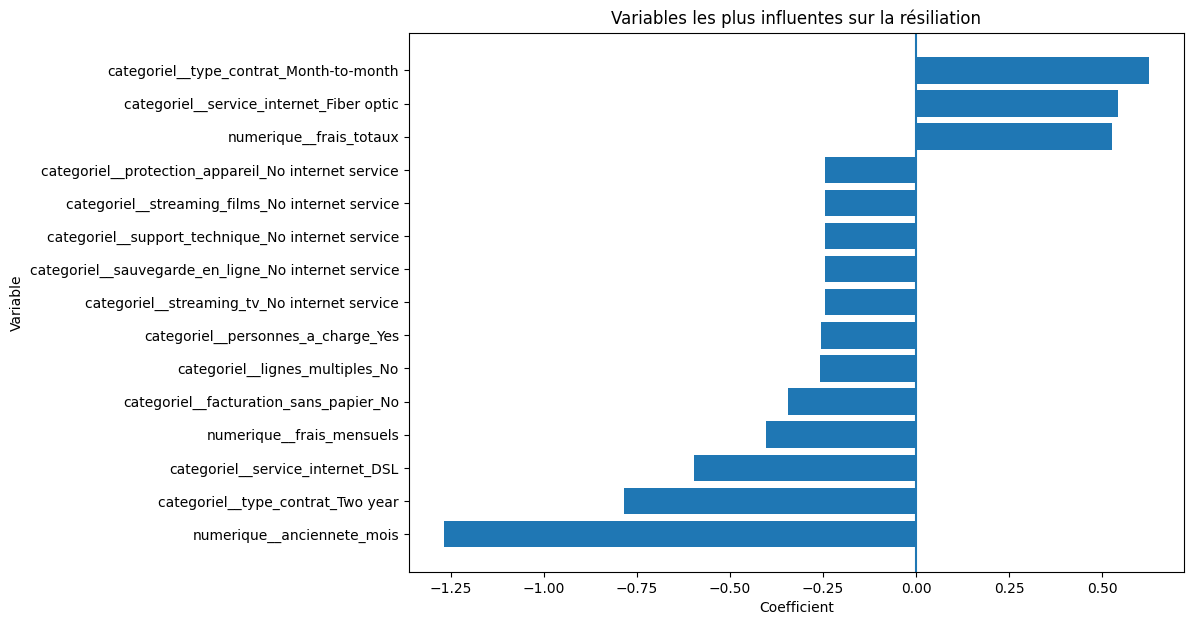

In [81]:
import matplotlib.pyplot as plt

top_variables = importance_logistique.head(15).sort_values(
    by='coefficient'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_variables['variable'],
    top_variables['coefficient']
)

plt.xlabel("Coefficient")
plt.ylabel("Variable")
plt.title(
    "Variables les plus influentes sur la résiliation"
)

plt.axvline(0)

plt.show()

In [82]:
importance_logistique.head(20)

,variable,coefficient,importance_absolue
1,numerique__anciennete_mois,-1.268079,1.268079
39,categoriel__type_contrat_Two year,-0.785708,0.785708
37,categoriel__type_contrat_Month-to-month,0.623789,0.623789
16,categoriel__service_internet_DSL,-0.597891,0.597891
17,categoriel__service_internet_Fiber optic,0.542346,0.542346
3,numerique__frais_totaux,0.524935,0.524935
2,numerique__frais_mensuels,-0.404022,0.404022
40,categoriel__facturation_sans_papier_No,-0.343525,0.343525
13,categoriel__lignes_multiples_No,-0.259744,0.259744
10,categoriel__personnes_a_charge_Yes,-0.256127,0.256127


In [83]:
import numpy as np

importance_logistique['odds_ratio'] = np.exp(
    importance_logistique['coefficient']
)

importance_logistique[
    ['variable', 'coefficient', 'odds_ratio']
].head(20)

,variable,coefficient,odds_ratio
1,numerique__anciennete_mois,-1.268079,0.281372
39,categoriel__type_contrat_Two year,-0.785708,0.455797
37,categoriel__type_contrat_Month-to-month,0.623789,1.865984
16,categoriel__service_internet_DSL,-0.597891,0.549971
17,categoriel__service_internet_Fiber optic,0.542346,1.720037
3,numerique__frais_totaux,0.524935,1.690349
2,numerique__frais_mensuels,-0.404022,0.667630
40,categoriel__facturation_sans_papier_No,-0.343525,0.709266
13,categoriel__lignes_multiples_No,-0.259744,0.771249
10,categoriel__personnes_a_charge_Yes,-0.256127,0.774044


In [84]:
import shap


In [85]:
preprocesseur_entraine = pipeline_logistique.named_steps['preprocessing']
modele_logistique = pipeline_logistique.named_steps['model']

In [86]:
X_test_transforme = preprocesseur_entraine.transform(X_test)

noms_variables = preprocesseur_entraine.get_feature_names_out()

In [87]:
print("X_test :", X_test.shape)
print("X_test transformé :", X_test_transforme.shape)
print("Nombre de variables :", len(noms_variables))

X_test : (1057, 23)
X_test transformé : (1057, 46)
Nombre de variables : 46


In [88]:
import shap

explainer = shap.LinearExplainer(
    modele_logistique,
    X_test_transforme
)

shap_values = explainer(X_test_transforme)

In [89]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


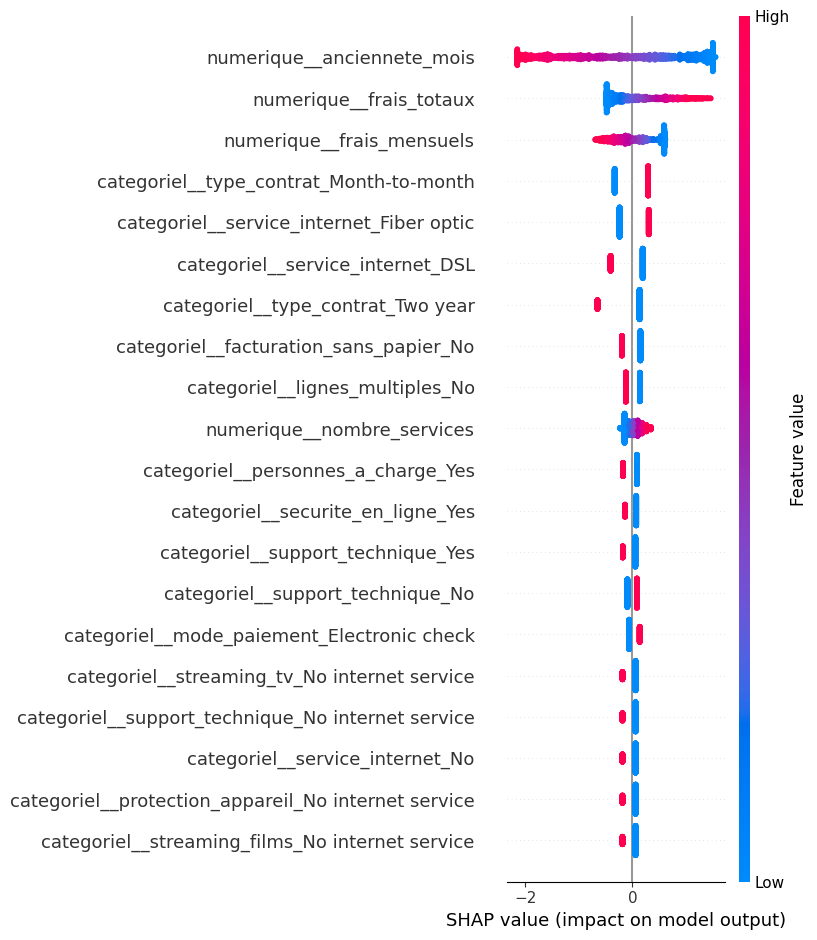

In [90]:
shap.summary_plot(
    shap_values.values,
    X_test_transforme,
    feature_names=noms_variables
)

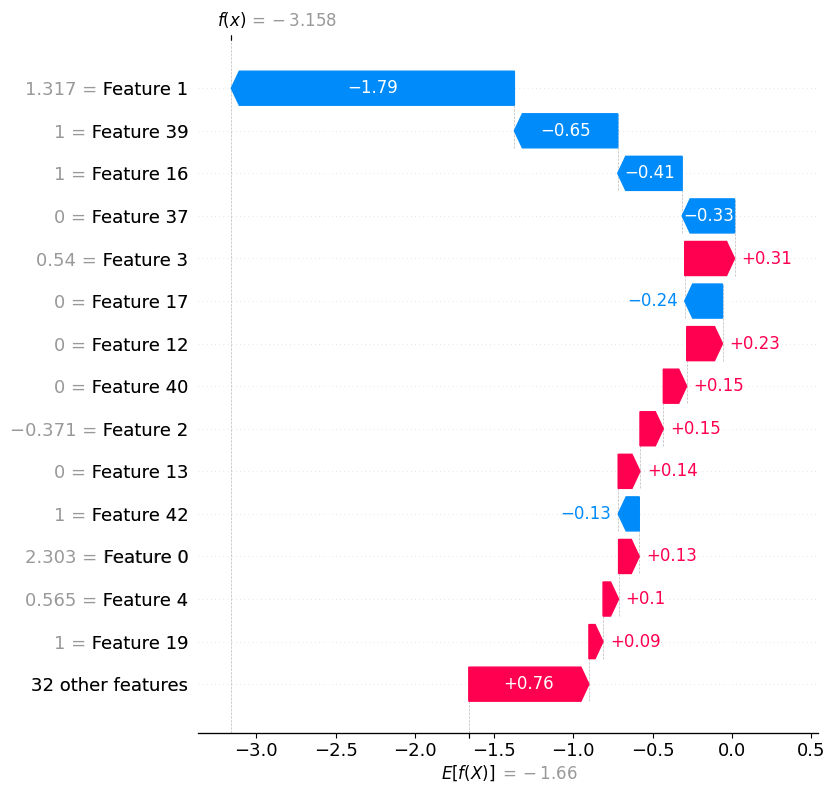

In [91]:
indice_client = 0

shap.plots.waterfall(
    shap_values[indice_client],
    max_display=15
)

In [92]:
proba_client = pipeline_logistique.predict_proba(
    X_test.iloc[[indice_client]]
)[0, 1]

print(
    "Probabilité de résiliation :",
    round(proba_client * 100, 2),
    "%"
)

Probabilité de résiliation : 4.08 %


In [93]:
X_test.iloc[[indice_client]]

,sexe,senior,partenaire,personnes_a_charge,anciennete_mois,service_telephone,lignes_multiples,service_internet,securite_en_ligne,sauvegarde_en_ligne,...,streaming_films,type_contrat,facturation_sans_papier,mode_paiement,frais_mensuels,frais_totaux,client_nouveau,contrat_mensuel,paiement_automatique,nombre_services
1584,Female,1,No,No,65,No,No phone service,DSL,No,Yes,...,Yes,Two year,Yes,Bank transfer (automatic),53.5,3517.9,0,0,1,4


In [94]:
X_test_transforme_df = pd.DataFrame(
    X_test_transforme,
    columns=noms_variables,
    index=X_test.index
)

explainer = shap.LinearExplainer(
    modele_logistique,
    X_test_transforme_df
)

shap_values = explainer(X_test_transforme_df)

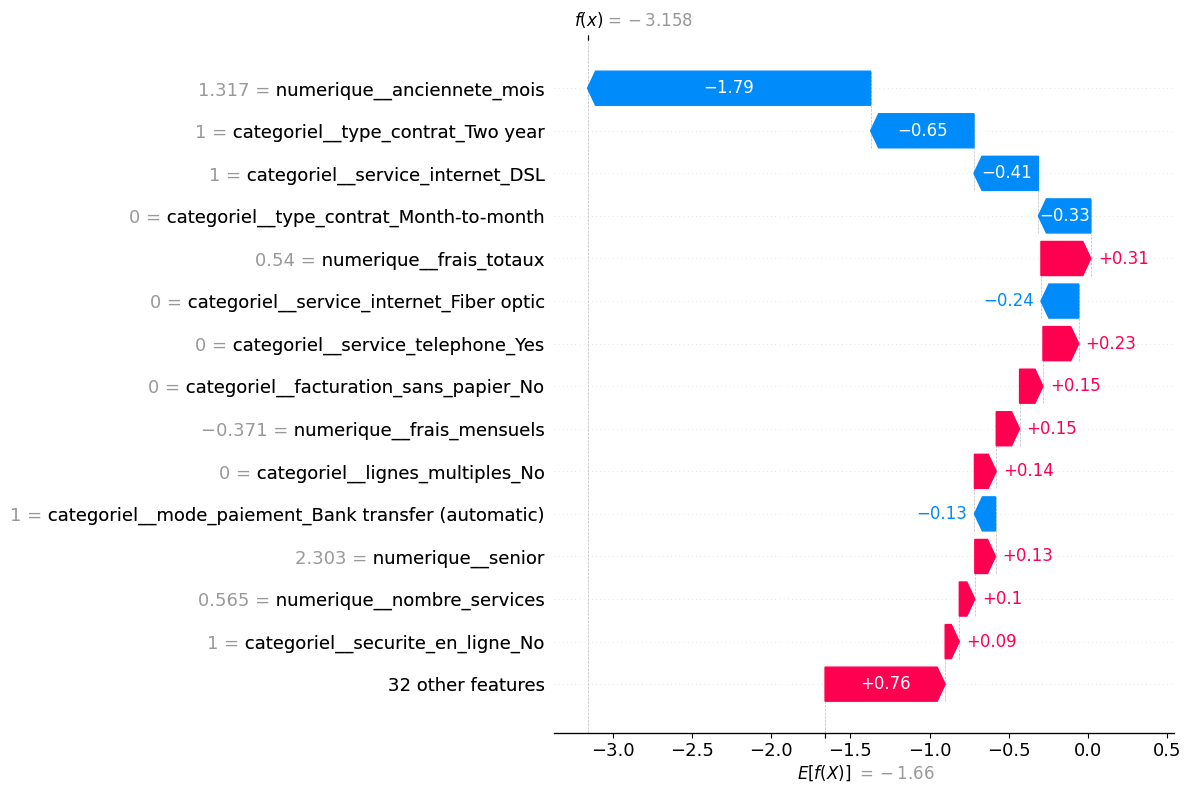

In [95]:
shap.plots.waterfall(
    shap_values[0],
    max_display=15
)

In [96]:
y_proba_test


array([0.04077162, 0.25246338, 0.04793828, ..., 0.27428728, 0.77917589,
       0.0394496 ])

In [97]:
resultats_clients = X_test.copy()
resultats_clients['probabilite_churn'] = y_proba_test


In [98]:
resultats_clients['niveau_risque'] = pd.cut(
    resultats_clients['probabilite_churn'],
    bins=[0, 0.30, 0.60, 1],
    labels=['Faible', 'Moyen', 'Élevé'],
    include_lowest=True
)

In [99]:
resultats_clients[
    ['probabilite_churn', 'niveau_risque']
].head()

,probabilite_churn,niveau_risque
1584,0.040772,Faible
6206,0.252463,Faible
6101,0.047938,Faible
6,0.480113,Moyen
1081,0.608389,Élevé


In [100]:
resultats_clients = X_test.copy()

resultats_clients['id_client'] = df.loc[
    X_test.index,
    'id_client'
]

# Probabilités du TEST FINAL
resultats_clients['probabilite_churn'] = y_proba_test


In [101]:
resultats_clients['niveau_risque'] = pd.cut(
    resultats_clients['probabilite_churn'],
    bins=[0, 0.30, 0.60, 1],
    labels=['Faible', 'Moyen', 'Élevé'],
    include_lowest=True
)

In [102]:
resultats_clients[
    ['id_client', 'probabilite_churn', 'niveau_risque']
].head(10)

,id_client,probabilite_churn,niveau_risque
1584,9906-NHHVC,0.040772,Faible
6206,2279-AXJJK,0.252463,Faible
6101,4627-MIHJH,0.047938,Faible
6,1452-KIOVK,0.480113,Moyen
1081,1751-NCDLI,0.608389,Élevé
522,0913-XWSCN,0.205543,Faible
4572,6377-WHAOX,0.458637,Moyen
4266,5445-PZWGX,0.083742,Faible
4824,3339-EAQNV,0.168791,Faible
6977,2843-CQMEG,0.210194,Faible


In [103]:
resultats_clients['niveau_risque'].value_counts()

niveau_risque
Faible    649
Moyen     244
Élevé     164
Name: count, dtype: int64

In [104]:
resultats_clients[
    ['id_client', 'probabilite_churn', 'niveau_risque']
].sort_values(
    by='probabilite_churn',
    ascending=False
).head(20)


,id_client,probabilite_churn,niveau_risque
3380,5178-LMXOP,0.844851,Élevé
2631,6861-XWTWQ,0.823169,Élevé
6866,0295-PPHDO,0.822906,Élevé
3346,2545-EBUPK,0.817186,Élevé
3727,9057-SIHCH,0.816353,Élevé
6894,1400-MMYXY,0.816001,Élevé
2797,6023-YEBUP,0.815959,Élevé
933,4750-ZRXIU,0.806516,Élevé
582,2865-TCHJW,0.805499,Élevé
935,6630-UJZMY,0.804558,Élevé


Calculer le revenu à risque

In [105]:
resultats_clients['revenu_annuel_estime'] = (
    resultats_clients['frais_mensuels'] * 12
)

resultats_clients['revenu_a_risque'] = (
    resultats_clients['revenu_annuel_estime']
    * resultats_clients['probabilite_churn']
)

In [106]:
resultats_clients[
    [
        'id_client',
        'frais_mensuels',
        'probabilite_churn',
        'niveau_risque',
        'revenu_annuel_estime',
        'revenu_a_risque'
    ]
].sort_values(
    by='revenu_a_risque',
    ascending=False
).head(20)

,id_client,frais_mensuels,probabilite_churn,niveau_risque,revenu_annuel_estime,revenu_a_risque
6894,1400-MMYXY,105.90,0.816001,Élevé,1270.8,1036.973892
2797,6023-YEBUP,100.95,0.815959,Élevé,1211.4,988.452944
2631,6861-XWTWQ,99.25,0.823169,Élevé,1191.0,980.394143
3380,5178-LMXOP,95.10,0.844851,Élevé,1141.2,964.143501
2294,2027-FECZV,106.70,0.745503,Élevé,1280.4,954.541631
3727,9057-SIHCH,96.60,0.816353,Élevé,1159.2,946.316014
1568,3292-PBZEJ,111.40,0.705332,Élevé,1336.8,942.887314
6866,0295-PPHDO,95.45,0.822906,Élevé,1145.4,942.556756
3085,5052-PNLOS,105.35,0.725340,Élevé,1264.2,916.974866
2246,7181-BQYBV,102.45,0.741258,Élevé,1229.4,911.302323


impact financier potentiel

In [107]:
def priorite_retention(ligne):
    if (
        ligne['probabilite_churn'] >= 0.60
        and ligne['revenu_a_risque'] >= 700
    ):
        return 'Priorité 1'
    
    elif ligne['probabilite_churn'] >= 0.40:
        return 'Priorité 2'
    
    else:
        return 'Priorité 3'


resultats_clients['priorite_retention'] = (
    resultats_clients.apply(
        priorite_retention,
        axis=1
    )
)

In [108]:
resultats_clients[
    'priorite_retention'
].value_counts()

priorite_retention
Priorité 3    720
Priorité 2    274
Priorité 1     63
Name: count, dtype: int64

In [109]:
resultats_clients[
    [
        'id_client',
        'frais_mensuels',
        'probabilite_churn',
        'revenu_a_risque',
        'priorite_retention'
    ]
].sort_values(
    by='revenu_a_risque',
    ascending=False
).head(20)

,id_client,frais_mensuels,probabilite_churn,revenu_a_risque,priorite_retention
6894,1400-MMYXY,105.90,0.816001,1036.973892,Priorité 1
2797,6023-YEBUP,100.95,0.815959,988.452944,Priorité 1
2631,6861-XWTWQ,99.25,0.823169,980.394143,Priorité 1
3380,5178-LMXOP,95.10,0.844851,964.143501,Priorité 1
2294,2027-FECZV,106.70,0.745503,954.541631,Priorité 1
3727,9057-SIHCH,96.60,0.816353,946.316014,Priorité 1
1568,3292-PBZEJ,111.40,0.705332,942.887314,Priorité 1
6866,0295-PPHDO,95.45,0.822906,942.556756,Priorité 1
3085,5052-PNLOS,105.35,0.725340,916.974866,Priorité 1
2246,7181-BQYBV,102.45,0.741258,911.302323,Priorité 1


In [110]:
cout_contact = 10
cout_offre = 50
taux_succes_retention = 0.30

campagne = resultats_clients[
    resultats_clients['priorite_retention'] == 'Priorité 1'
].copy()

campagne['cout_campagne'] = cout_contact + cout_offre

campagne['revenu_sauve_estime'] = (
    campagne['revenu_a_risque']
    * taux_succes_retention
)

campagne['gain_net_estime'] = (
    campagne['revenu_sauve_estime']
    - campagne['cout_campagne']
)

campagne['roi_estime'] = (
    campagne['gain_net_estime']
    / campagne['cout_campagne']
) * 100

In [111]:
campagne[
    [
        'id_client',
        'probabilite_churn',
        'revenu_a_risque',
        'cout_campagne',
        'revenu_sauve_estime',
        'gain_net_estime',
        'roi_estime'
    ]
].sort_values(
    by='roi_estime',
    ascending=False
).head(20)

,id_client,probabilite_churn,revenu_a_risque,cout_campagne,revenu_sauve_estime,gain_net_estime,roi_estime
6894,1400-MMYXY,0.816001,1036.973892,60,311.092168,251.092168,418.486946
2797,6023-YEBUP,0.815959,988.452944,60,296.535883,236.535883,394.226472
2631,6861-XWTWQ,0.823169,980.394143,60,294.118243,234.118243,390.197071
3380,5178-LMXOP,0.844851,964.143501,60,289.243050,229.243050,382.071751
2294,2027-FECZV,0.745503,954.541631,60,286.362489,226.362489,377.270815
3727,9057-SIHCH,0.816353,946.316014,60,283.894804,223.894804,373.158007
1568,3292-PBZEJ,0.705332,942.887314,60,282.866194,222.866194,371.443657
6866,0295-PPHDO,0.822906,942.556756,60,282.767027,222.767027,371.278378
3085,5052-PNLOS,0.725340,916.974866,60,275.092460,215.092460,358.487433
2246,7181-BQYBV,0.741258,911.302323,60,273.390697,213.390697,355.651161


In [112]:
cout_total = campagne['cout_campagne'].sum()

revenu_sauve_total = (
    campagne['revenu_sauve_estime'].sum()
)

gain_net_total = (
    campagne['gain_net_estime'].sum()
)

roi_global = (
    gain_net_total / cout_total
) * 100

print("Nombre de clients ciblés :", len(campagne))
print("Coût total de la campagne :", round(cout_total, 2))
print("Revenu sauvé estimé :", round(revenu_sauve_total, 2))
print("Gain net estimé :", round(gain_net_total, 2))
print("ROI global estimé :", round(roi_global, 2), "%")

Nombre de clients ciblés : 63
Coût total de la campagne : 3780
Revenu sauvé estimé : 15486.89
Gain net estimé : 11706.89
ROI global estimé : 309.71 %


In [113]:
scenarios = {
    'Pessimiste': 0.10,
    'Realiste': 0.30,
    'Optimiste': 0.50
}

resultats_scenarios = []

for nom_scenario, taux_succes in scenarios.items():

    revenu_sauve = (
        campagne['revenu_a_risque'].sum()
        * taux_succes
    )

    cout_total = campagne['cout_campagne'].sum()

    gain_net = revenu_sauve - cout_total

    roi = (
        gain_net / cout_total
    ) * 100

    resultats_scenarios.append({
        'scenario': nom_scenario,
        'taux_succes': taux_succes,
        'cout_total': cout_total,
        'revenu_sauve_estime': revenu_sauve,
        'gain_net_estime': gain_net,
        'roi_estime': roi
    })

In [114]:
comparaison_scenarios = pd.DataFrame(
    resultats_scenarios
)

comparaison_scenarios.round(2)

,scenario,taux_succes,cout_total,revenu_sauve_estime,gain_net_estime,roi_estime
0,Pessimiste,0.1,3780,5162.30,1382.30,36.57
1,Realiste,0.3,3780,15486.89,11706.89,309.71
2,Optimiste,0.5,3780,25811.49,22031.49,582.84


### Interprétation des scénarios

Les valeurs ci-dessus sont des **simulations** fondées sur des hypothèses de coût et de taux de succès. Les résultats affichés après exécution du notebook doivent être utilisés dans la conclusion finale, sans reprendre d'anciens chiffres calculés avec un autre découpage des données.


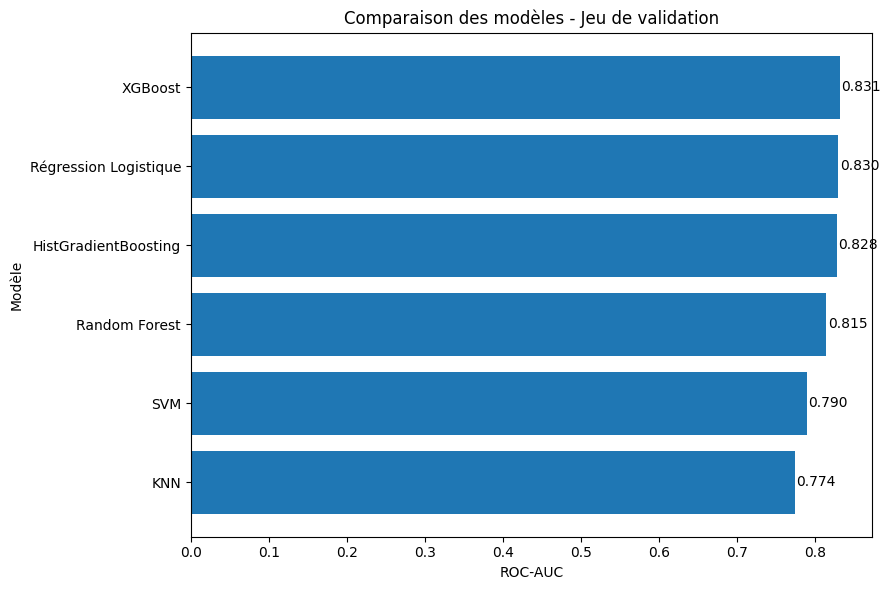

In [115]:
import matplotlib.pyplot as plt

graph_modeles = comparaison_modeles[
    ['Modèle', 'ROC-AUC']
].sort_values(by='ROC-AUC', ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(
    graph_modeles['Modèle'],
    graph_modeles['ROC-AUC']
)

plt.xlabel('ROC-AUC')
plt.ylabel('Modèle')
plt.title('Comparaison des modèles - Jeu de validation')

for idx, value in enumerate(graph_modeles['ROC-AUC']):
    plt.text(
        value + 0.002,
        idx,
        f'{value:.3f}',
        va='center'
    )

plt.tight_layout()
plt.show()


## Visualisations finales du modèle et de l'impact business


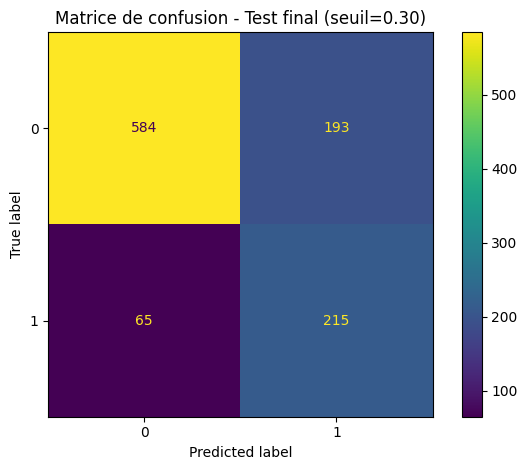

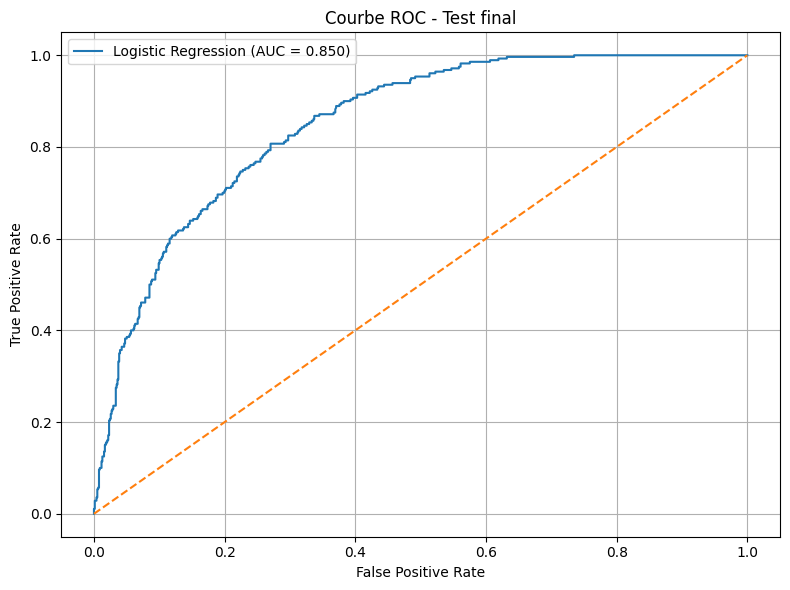

In [116]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

# Matrice de confusion sur TEST FINAL
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test)
plt.title(f'Matrice de confusion - Test final (seuil={seuil_final:.2f})')
plt.tight_layout()
plt.show()

# Courbe ROC sur TEST FINAL
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
auc_test = roc_auc_score(y_test, y_proba_test)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_test:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - Test final')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


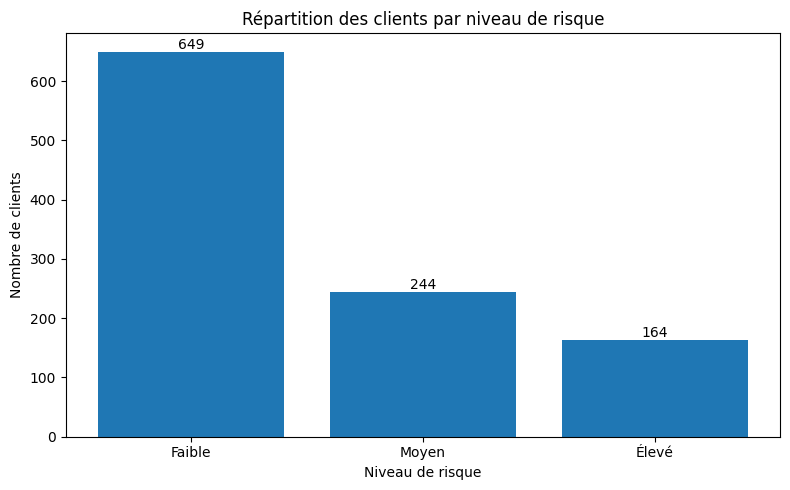

In [117]:
# Répartition des clients par niveau de risque
repartition_risque = (
    resultats_clients['niveau_risque']
    .value_counts()
    .reindex(['Faible', 'Moyen', 'Élevé'])
    .fillna(0)
)

plt.figure(figsize=(8, 5))
plt.bar(repartition_risque.index, repartition_risque.values)
plt.xlabel('Niveau de risque')
plt.ylabel('Nombre de clients')
plt.title('Répartition des clients par niveau de risque')

for idx, value in enumerate(repartition_risque.values):
    plt.text(idx, value, str(int(value)), ha='center', va='bottom')

plt.tight_layout()
plt.show()


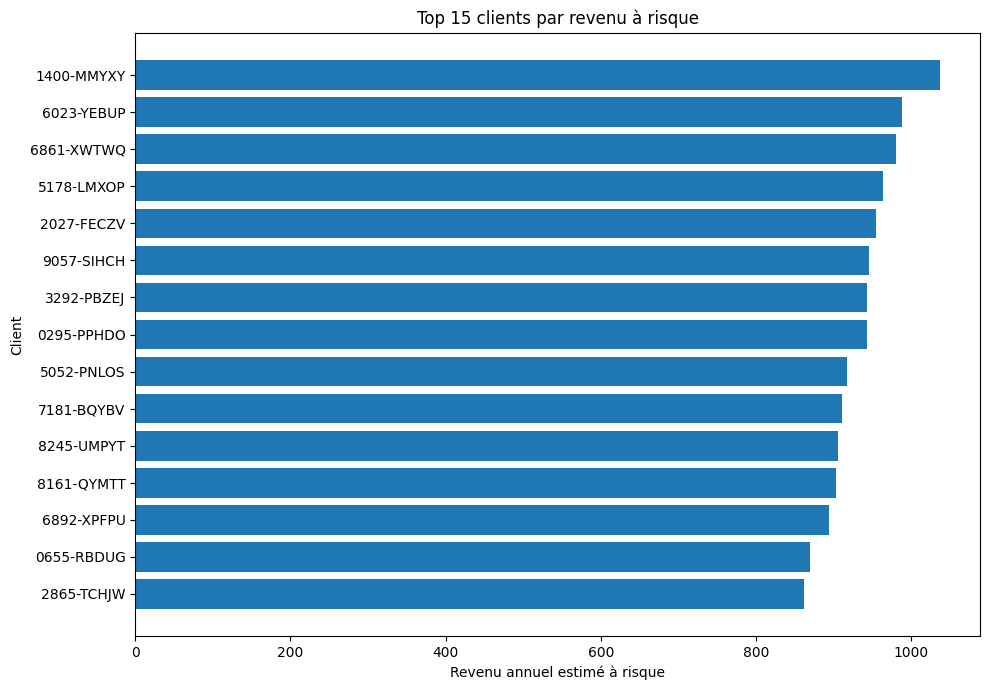

In [118]:
# Top 15 clients par revenu annuel estimé à risque
top_risque = (
    resultats_clients[['id_client', 'revenu_a_risque']]
    .sort_values(by='revenu_a_risque', ascending=False)
    .head(15)
    .sort_values(by='revenu_a_risque')
)

plt.figure(figsize=(10, 7))
plt.barh(top_risque['id_client'], top_risque['revenu_a_risque'])
plt.xlabel('Revenu annuel estimé à risque')
plt.ylabel('Client')
plt.title('Top 15 clients par revenu à risque')
plt.tight_layout()
plt.show()


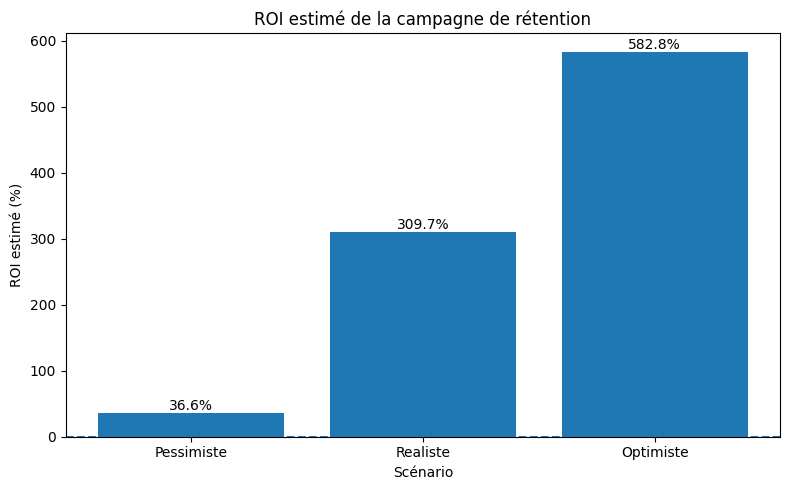

In [119]:
# ROI selon les scénarios de campagne
plt.figure(figsize=(8, 5))
plt.bar(
    comparaison_scenarios['scenario'],
    comparaison_scenarios['roi_estime']
)

plt.xlabel('Scénario')
plt.ylabel('ROI estimé (%)')
plt.title('ROI estimé de la campagne de rétention')

for idx, value in enumerate(comparaison_scenarios['roi_estime']):
    plt.text(idx, value, f'{value:.1f}%', ha='center', va='bottom')

plt.axhline(0, linestyle='--')
plt.tight_layout()
plt.show()


In [120]:
scoring_powerbi = resultats_clients.copy()

scoring_powerbi['churn_reel'] = df.loc[
    scoring_powerbi.index,
    'resiliation'
]

scoring_powerbi.to_csv(
    'scoring_clients_powerbi.csv',
    index=False,
    encoding='utf-8-sig'
)

print(scoring_powerbi.shape)
scoring_powerbi.head()

(1057, 30)


,sexe,senior,partenaire,personnes_a_charge,anciennete_mois,service_telephone,lignes_multiples,service_internet,securite_en_ligne,sauvegarde_en_ligne,...,contrat_mensuel,paiement_automatique,nombre_services,id_client,probabilite_churn,niveau_risque,revenu_annuel_estime,revenu_a_risque,priorite_retention,churn_reel
1584,Female,1,No,No,65,No,No phone service,DSL,No,Yes,...,0,1,4,9906-NHHVC,0.040772,Faible,642.0,26.175377,Priorité 3,No
6206,Male,0,Yes,No,52,Yes,Yes,Fiber optic,No,Yes,...,1,1,4,2279-AXJJK,0.252463,Faible,1147.8,289.777462,Priorité 3,No
6101,Female,1,No,No,69,Yes,Yes,Fiber optic,Yes,No,...,0,1,6,4627-MIHJH,0.047938,Faible,1323.0,63.422344,Priorité 3,No
6,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,...,1,1,3,1452-KIOVK,0.480113,Moyen,1069.2,513.336855,Priorité 2,No
1081,Male,1,Yes,No,46,Yes,Yes,Fiber optic,No,No,...,1,0,4,1751-NCDLI,0.608389,Élevé,1186.2,721.670476,Priorité 1,No


In [121]:
comparaison_scenarios.to_csv(
    "comparaison_scenarios.csv",
    index=False,
    encoding="utf-8-sig"
)

In [122]:
comparaison_modeles.to_csv(
    "comparaison_modeles.csv",
    index=False,
    encoding="utf-8-sig"
)

In [123]:
importance_logistique.to_csv(
    "importance_variables.csv",
    index=False,
    encoding="utf-8-sig"
)